In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/m5_subset.csv", parse_dates=["date"])
print(df.shape)
df.head()

(292000, 16)


,item_id,dept_id,cat_id,store_id,state_id,d,units,date,wm_yr_wk,wday,month,year,event_name_1,event_type_1,snap,sell_price
0,FOODS_1_096,FOODS_1,FOODS,CA_1,CA,d_1212,0,2014-05-24,11417,1,5,2014,none,none,0,5.69
1,FOODS_1_096,FOODS_1,FOODS,CA_1,CA,d_1213,2,2014-05-25,11417,2,5,2014,none,none,0,5.69
2,FOODS_1_096,FOODS_1,FOODS,CA_1,CA,d_1214,0,2014-05-26,11417,3,5,2014,MemorialDay,National,0,5.69
3,FOODS_1_096,FOODS_1,FOODS,CA_1,CA,d_1215,0,2014-05-27,11417,4,5,2014,none,none,0,5.69
4,FOODS_1_096,FOODS_1,FOODS,CA_1,CA,d_1216,0,2014-05-28,11417,5,5,2014,none,none,0,5.69


In [2]:
zero_share = df.groupby("item_id")["units"].apply(lambda s: (s == 0).mean()).sort_values(ascending=False)
zero_share.head(10)

item_id
FOODS_3_541    0.451507
FOODS_2_360    0.445205
FOODS_3_635    0.411507
FOODS_3_329    0.403151
FOODS_3_808    0.398493
FOODS_3_007    0.394110
FOODS_3_318    0.357534
FOODS_3_234    0.340822
FOODS_3_362    0.310548
FOODS_3_752    0.293288
Name: units, dtype: float64

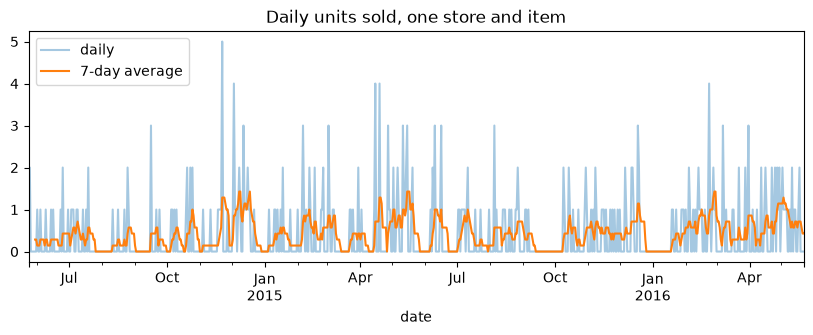

In [3]:
one = df[(df.store_id == "CA_1") & (df.item_id == df.item_id.iloc[0])].set_index("date")
fig, ax = plt.subplots(figsize=(10, 3))
one["units"].plot(ax=ax, alpha=0.4, label="daily")
one["units"].rolling(7).mean().plot(ax=ax, label="7-day average")
ax.set_title("Daily units sold, one store and item")
ax.legend()
plt.show()

In [4]:
print(df.groupby("wday")["units"].mean().round(2))
print(df.groupby("snap")["units"].mean().round(2))

wday
1    17.98
2    18.13
3    13.95
4    12.98
5    12.89
6    13.19
7    14.91
Name: units, dtype: float64
snap
0    14.36
1    15.90
Name: units, dtype: float64


In [5]:
s = df[df.store_id == "CA_1"].groupby("item_id")["units"].agg(["mean", "std"])
s["cv"] = s["std"] / s["mean"]   # higher = more uncertain relative to its size
s.sort_values("cv").tail(10)

,mean,std,cv
item_id,,,
FOODS_3_318,8.957534,9.714278,1.084481
FOODS_2_360,7.280822,8.404505,1.154335
FOODS_3_541,11.600000,15.944571,1.374532
FOODS_3_808,10.249315,14.277604,1.393030
FOODS_3_234,6.927397,9.650203,1.393049
FOODS_3_007,4.439726,6.499324,1.463902
FOODS_3_804,2.060274,3.167338,1.537338
FOODS_3_752,5.069863,7.998580,1.577672
FOODS_3_635,8.836986,14.847538,1.680159


In [6]:
df = df.sort_values(["store_id", "item_id", "date"]).reset_index(drop=True)

def zero_run_lengths(s):
    """For each day: length of the zero-run it belongs to (0 if units > 0)."""
    is_zero = (s == 0)
    run_id = (is_zero != is_zero.shift()).cumsum()
    return is_zero.groupby(run_id).transform("sum")

df["zero_run"] = df.groupby(["store_id", "item_id"])["units"].transform(zero_run_lengths)

MIN_LEN = 7
df["in_long_zero_run"] = (df["units"] == 0) & (df["zero_run"] >= MIN_LEN)

per_series = df.groupby(["store_id", "item_id"]).agg(
    mean_units=("units", "mean"),
    longest_zero_run=("zero_run", "max"),
    share_in_long_runs=("in_long_zero_run", "mean"),
)
print(per_series.sort_values("share_in_long_runs", ascending=False).head(10).round(3))
print("share of all days inside zero runs of 7+ days: %.1f%%" % (100 * df["in_long_zero_run"].mean()))

                      mean_units  longest_zero_run  share_in_long_runs
store_id item_id                                                      
WI_3     FOODS_3_541       4.073                96               0.593
TX_3     FOODS_3_541       6.748                88               0.507
         FOODS_3_808       8.544                97               0.478
WI_3     FOODS_3_635       5.085                95               0.477
WI_2     FOODS_2_360      24.156               178               0.456
TX_2     FOODS_3_808       8.478                91               0.447
TX_1     FOODS_3_635       8.040                82               0.447
TX_2     FOODS_3_635       9.519                89               0.441
TX_1     FOODS_3_541       7.995               144               0.440
WI_1     FOODS_2_360       8.516               187               0.438
share of all days inside zero runs of 7+ days: 11.4%


In [7]:
df = pd.read_csv("../data/processed/m5_subset.csv", parse_dates=["date"])

by_item = df.groupby("item_id")["unavailable"].mean().sort_values(ascending=False)
print(by_item.head(10).round(3))
print((by_item > 0.25).sum(), "items with >25% unavailable days")

by_series = df.groupby(["store_id", "item_id"])["unavailable"].mean()
print((by_series > 0.5).sum(), "series with >50% of days unavailable")

item_id
FOODS_2_360    0.385
FOODS_3_329    0.383
FOODS_3_541    0.379
FOODS_3_635    0.350
FOODS_3_808    0.342
FOODS_3_318    0.323
FOODS_3_362    0.280
FOODS_3_723    0.181
FOODS_3_202    0.180
FOODS_3_090    0.179
Name: unavailable, dtype: float64
7 items with >25% unavailable days
2 series with >50% of days unavailable
